In [1]:
!pip3 install numpy matplotlib

In [2]:
# Linear Least Squares demo in 3D
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Generate synthetic linear data
np.random.seed(42)

# True model parameters (plane: z = a*x + b*y + c)
a, b, c = 2.0, -1.0, 5.0

# Generate random x, y values
N = 200
INLIERS_PERC = 0.9
INLIERS = int(N * INLIERS_PERC)
x = np.random.uniform(-5, 5, N)
y = np.random.uniform(-5, 5, N)

# Compute noiseless z values
z_true = a * x + b * y + c

In [3]:
# 2. Add Gaussian noise
z_noisy = z_true

noise = np.random.normal(0, 1.2, INLIERS)
z_noisy[0:INLIERS] = z_true[0:INLIERS] + noise

noise_outliers = np.random.normal(0, 5, N - INLIERS)
z_noisy[INLIERS:] = z_true[INLIERS:] + noise_outliers

In [4]:
# 3. Fit with Linear Least Squares
# Design matrix [x, y, 1]
A = np.vstack([x, y, np.ones(N)]).T

# Solve the system Ax = b
# |x_0 y_0 1| |a|   |z_0|
# | .   .  .| |b| = | . |
# |x_n y_n 1| |c|   |z_n|
params, _, _, _ = np.linalg.lstsq(A.T @ A, A.T @ z_noisy)
a_hat, b_hat, c_hat = params

print("True parameters:   a=%.2f, b=%.2f, c=%.2f" % (a, b, c))
print("Estimated params:  a=%.2f, b=%.2f, c=%.2f" % (a_hat, b_hat, c_hat))

# Compute RMSE
z_pred = A @ params
rmse = np.sqrt(np.mean((z_noisy - z_pred)**2))
print("RMSE: %.3f" % rmse)


True parameters:   a=2.00, b=-1.00, c=5.00
Estimated params:  a=1.97, b=-1.10, c=4.92
RMSE: 1.806


In [5]:
# 3. Fit with Weighted Linear Least Squares
# Design matrix [x, y, 1]
A = np.vstack([x, y, np.ones(N)]).T

# Solve the system with WLS
W = np.ones(N)
W[0:INLIERS] = 1
W[INLIERS:] = 0.1
W = np.diag(W)
params, _, _, _ = np.linalg.lstsq(A.T @ W @ A, A.T @ W @ z_noisy)
a_hat_w, b_hat_w, c_hat_w = params

print("True parameters:   a=%.2f, b=%.2f, c=%.2f" % (a, b, c))
print("Estimated params:  a=%.2f, b=%.2f, c=%.2f" % (a_hat_w, b_hat_w, c_hat_w))

# Compute RMSE
z_pred = A @ params
rmse_w = np.sqrt(np.mean(W @ (z_noisy - z_pred)**2))
print("RMSE: %.3f" % rmse_w)

True parameters:   a=2.00, b=-1.00, c=5.00
Estimated params:  a=2.01, b=-1.01, c=5.01
RMSE: 0.086


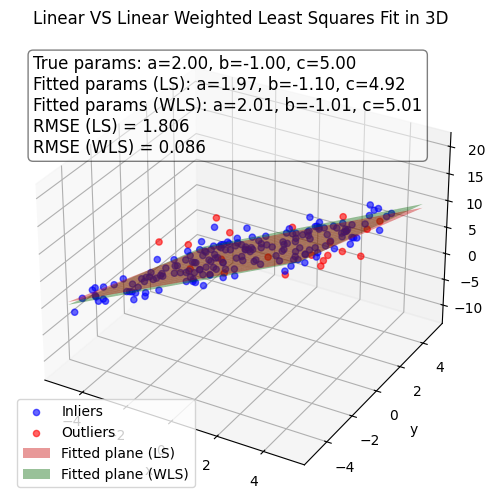

In [6]:
# 5. Plot results
fig = plt.figure(figsize=(12,6))
ax = fig.add_subplot(111, projection="3d")

# Scatter noisy data
ax.scatter(x[:INLIERS], y[:INLIERS], z_noisy[:INLIERS], color="blue", alpha=0.6, label="Inliers")
ax.scatter(x[INLIERS:], y[INLIERS:], z_noisy[INLIERS:], color="red", alpha=0.6, label="Outliers")

# Plot fitted plane
xx, yy = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
zz = a_hat * xx + b_hat * yy + c_hat
ax.plot_surface(xx, yy, zz, alpha=0.4, color="red", label="Fitted plane (LS)")

zz = a_hat_w * xx + b_hat_w * yy + c_hat_w
ax.plot_surface(xx, yy, zz, alpha=0.4, color="green", label="Fitted plane (WLS)")

# Annotate parameters and RMSE
textstr = '\n'.join((
    f"True params: a={a:.2f}, b={b:.2f}, c={c:.2f}",
    f"Fitted params (LS): a={a_hat:.2f}, b={b_hat:.2f}, c={c_hat:.2f}",
    f"Fitted params (WLS): a={a_hat_w:.2f}, b={b_hat_w:.2f}, c={c_hat_w:.2f}",
    f"RMSE (LS) = {rmse:.3f}",
    f"RMSE (WLS) = {rmse_w:.3f}"
))
ax.text2D(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
          verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))


ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Linear VS Linear Weighted Least Squares Fit in 3D")
plt.legend()
plt.show()